In [1]:
# 1. Import library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files

# Upload dataset saham CSV
uploaded = files.upload()

Saving dataset_saham_sintetis.csv to dataset_saham_sintetis.csv


In [2]:
# 2. Membaca dataset
file_name = next(iter(uploaded))
df = pd.read_csv(file_name)
df.columns = df.columns.str.strip()

print("Ukuran dataset:", df.shape)
print("Kolom dataset:", df.columns.tolist())
display(df.head())

Ukuran dataset: (260, 6)
Kolom dataset: ['Date', 'Open', 'High', 'Low', 'Close', 'Volume']


,Date,Open,High,Low,Close,Volume
0,2025-01-02,10073.90,10094.00,9931.04,10040.15,9360133
1,2025-01-03,10061.43,10098.15,9893.57,9919.10,10750049
2,2025-01-06,9926.90,10044.17,9817.54,10012.33,9926512
3,2025-01-07,10033.20,10143.68,10022.57,10129.52,10511316
4,2025-01-08,10163.13,10241.03,9801.42,9898.58,7365135


In [3]:
# 3. Membersihkan data
if 'Date' not in df.columns or 'Close' not in df.columns:
    raise ValueError("CSV wajib memiliki kolom Date dan Close.")

df['Date'] = pd.to_datetime(df['Date'], errors='coerce')
df['Close'] = pd.to_numeric(
    df['Close'].astype(str).str.replace(',', '', regex=False),
    errors='coerce'
)

df = (df.dropna(subset=['Date', 'Close'])
        .drop_duplicates()
        .sort_values('Date')
        .reset_index(drop=True))

print("Jumlah data setelah dibersihkan:", len(df))
display(df[['Date', 'Close']].head())

Jumlah data setelah dibersihkan: 260


,Date,Close
0,2025-01-02,10040.15
1,2025-01-03,9919.10
2,2025-01-06,10012.33
3,2025-01-07,10129.52
4,2025-01-08,9898.58


In [4]:
# 4. Menghitung perubahan harga dan pola pergerakan
df['Perubahan_Harga'] = df['Close'].diff()
df['Perubahan_Persen'] = df['Close'].pct_change() * 100

def tentukan_pola(perubahan):
    if pd.isna(perubahan):
        return 'Belum ada pembanding'
    elif perubahan > 0:
        return 'Naik'
    elif perubahan < 0:
        return 'Turun'
    return 'Tetap'

df['Pola'] = df['Perubahan_Harga'].apply(tentukan_pola)
display(df[['Date', 'Close', 'Perubahan_Harga', 'Perubahan_Persen', 'Pola']].head(10))

,Date,Close,Perubahan_Harga,Perubahan_Persen,Pola
0,2025-01-02,10040.15,NaN,NaN,Belum ada pembanding
1,2025-01-03,9919.10,-121.05,-1.205659,Turun
2,2025-01-06,10012.33,93.23,0.939904,Naik
3,2025-01-07,10129.52,117.19,1.170457,Naik
4,2025-01-08,9898.58,-230.94,-2.279871,Turun
5,2025-01-09,9748.52,-150.06,-1.515975,Turun
6,2025-01-10,9766.90,18.38,0.188541,Naik
7,2025-01-13,9733.32,-33.58,-0.343814,Turun
8,2025-01-14,9734.76,1.44,0.014795,Naik
9,2025-01-15,9638.99,-95.77,-0.983794,Turun


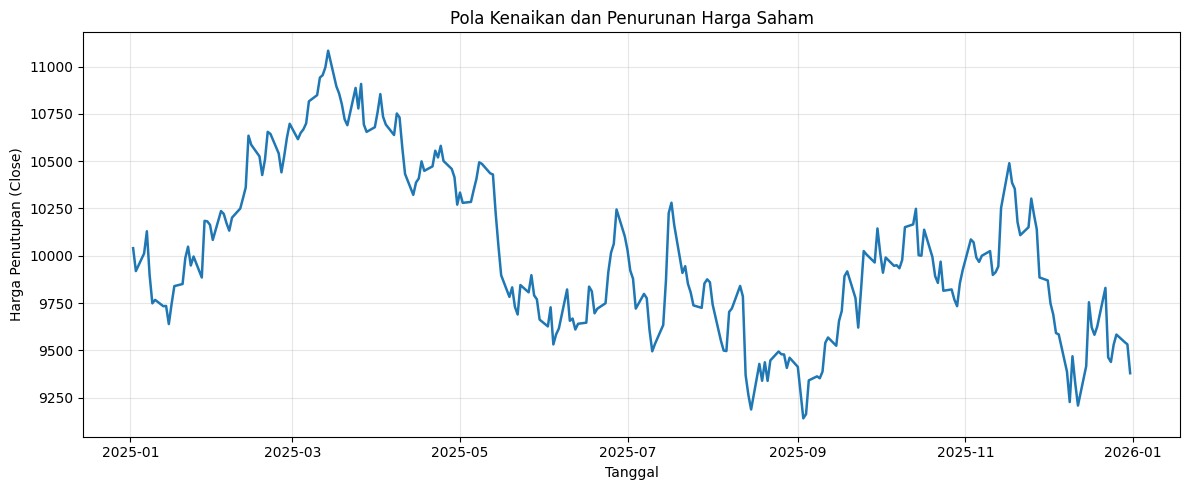

In [5]:
# 5. Grafik garis pola harga saham
plt.figure(figsize=(12, 5))
plt.plot(df['Date'], df['Close'], linewidth=1.8)
plt.title('Pola Kenaikan dan Penurunan Harga Saham')
plt.xlabel('Tanggal')
plt.ylabel('Harga Penutupan (Close)')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

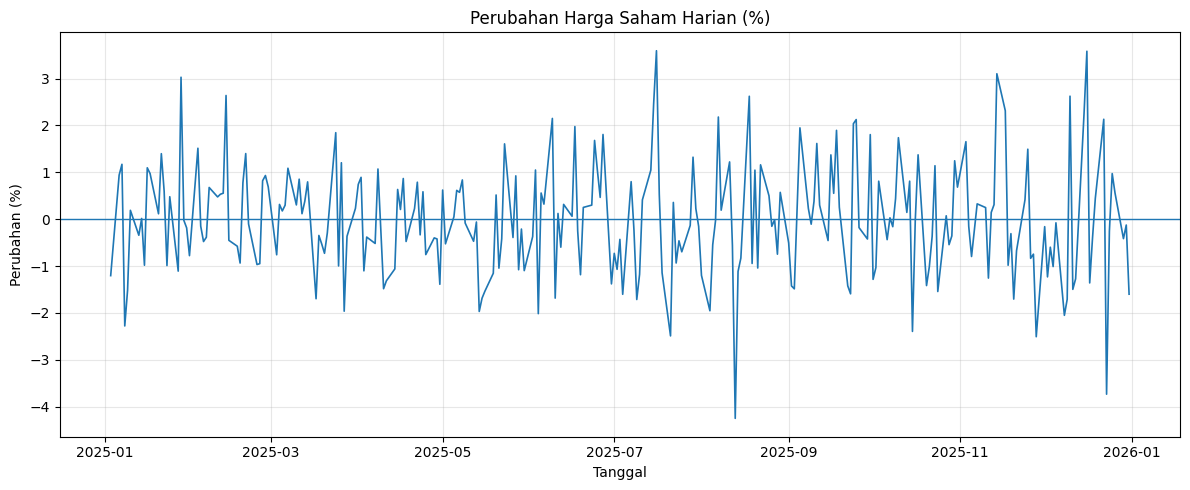

In [6]:
# 6. Grafik perubahan persentase harian
data_perubahan = df.dropna(subset=['Perubahan_Persen'])

plt.figure(figsize=(12, 5))
plt.plot(data_perubahan['Date'], data_perubahan['Perubahan_Persen'], linewidth=1.2)
plt.axhline(0, linewidth=1)
plt.title('Perubahan Harga Saham Harian (%)')
plt.xlabel('Tanggal')
plt.ylabel('Perubahan (%)')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Jumlah hari berdasarkan pola:


,Jumlah Hari
Pola,
Turun,137
Naik,122


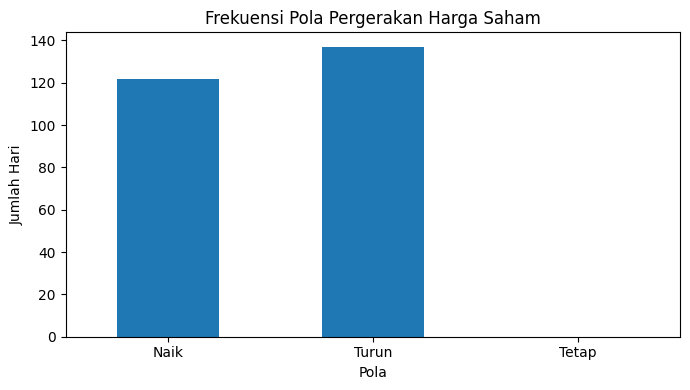

In [7]:
# 7. Ringkasan jumlah pola naik, turun, dan tetap
ringkasan = df.loc[df['Pola'].isin(['Naik', 'Turun', 'Tetap']), 'Pola'].value_counts()
print("Jumlah hari berdasarkan pola:")
display(ringkasan.rename_axis('Pola').to_frame('Jumlah Hari'))

plt.figure(figsize=(7, 4))
ringkasan.reindex(['Naik', 'Turun', 'Tetap'], fill_value=0).plot(kind='bar')
plt.title('Frekuensi Pola Pergerakan Harga Saham')
plt.xlabel('Pola')
plt.ylabel('Jumlah Hari')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [8]:
# 8. Ringkasan statistik
print("Periode data:", df['Date'].min().date(), "sampai", df['Date'].max().date())
print(f"Harga penutupan terendah: {df['Close'].min():,.2f}")
print(f"Harga penutupan tertinggi: {df['Close'].max():,.2f}")
print(f"Harga penutupan awal: {df['Close'].iloc[0]:,.2f}")
print(f"Harga penutupan akhir: {df['Close'].iloc[-1]:,.2f}")

perubahan_total = (df['Close'].iloc[-1] / df['Close'].iloc[0] - 1) * 100
print(f"Perubahan total selama periode: {perubahan_total:.2f}%")

if perubahan_total > 0:
    print("Kesimpulan awal: harga akhir lebih tinggi daripada harga awal.")
elif perubahan_total < 0:
    print("Kesimpulan awal: harga akhir lebih rendah daripada harga awal.")
else:
    print("Kesimpulan awal: harga akhir sama dengan harga awal.")

Periode data: 2025-01-02 sampai 2025-12-31
Harga penutupan terendah: 9,140.60
Harga penutupan tertinggi: 11,083.95
Harga penutupan awal: 10,040.15
Harga penutupan akhir: 9,379.05
Perubahan total selama periode: -6.58%
Kesimpulan awal: harga akhir lebih rendah daripada harga awal.
